In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
import os
import sys
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "..")))
from ants_move_special import *
import pygame

pygame 2.5.2 (SDL 2.28.2, Python 3.10.12)
Hello from the pygame community. https://www.pygame.org/contribute.html


In [ ]:
n = 300
Lx = 32
Ly = 32
delta = 0.3
beta = 4.5
eta = 0.01
decay_rate = 0.015
eta_special = 1
n_special = 30
t_transient = 200
tmax = 800
k = 2
beta_special = 4.5
delta_special = 0.3

In [3]:
def reward(env, site):
    env.compute_density()
    return env.rho[site[0], site[1]]

In [4]:
def compute_avg_res(beta_special, delta_special):

    # rew_n_list = []
    rew_list = []

    k = 2
    env = Ants_move_special(n, Lx, Ly, delta, beta, decay_rate, eta, eta_special,
                            beta_special, delta_special, tmax, n_special, t_transient)

    env.reset_objects()
    env.transient()

    # res = np.zeros(8)

    for t in range(1000):

        s0 = env.avg_pher()
        
        env.update()

        env.order_parameter_s()
        env.compute_density()
        env.order_parameter_p() 
        env.avg_pher()

        rews = [reward(env, site) for site in env.positions[env.n:]]
        # rews_n = [reward_n(component_map,  env, site[0], site[1], alpha)[3] for site in env.positions[env.n:]]
        #rews = [item if item is not None else [0, 0, 0] for item in rews]

        # rew_n_list.append(rews_n)
        rew_list.append(rews)

    rew_list = np.array(rew_list)
    #rew_n_list = np.array(rew_n_list)

    # res = np.concatenate((rew_list,rew_n_list), axis=2)
    avg_res = np.mean(rew_list)#, axis=(0,1))

    return avg_res

In [5]:
beta_list = np.linspace(1.5, 6.5, 6)
delta_list = np.linspace(0.1, 0.5, 5)

res_matrix_n = np.zeros((len(beta_list), len(delta_list), 1))

for i, beta_s in enumerate(beta_list):
    for j, delta_s in enumerate(delta_list):

        print(i,j)
        res_matrix_n[i,j,:] = compute_avg_res(beta_special=beta_s, delta_special=delta_s)

0 0
0 1
0 2
0 3
0 4
1 0
1 1
1 2
1 3
1 4
2 0
2 1
2 2
2 3
2 4
3 0
3 1
3 2
3 3
3 4
4 0
4 1
4 2
4 3
4 4
5 0
5 1
5 2
5 3
5 4


In [6]:
res_matrix_n.shape

(6, 5, 1)

In [7]:
def beta_crit(d, s0):
    return 1 + 1/s0 + 2*d + d*s0 + d**2*s0

s0 = (n*eta + n_special*eta_special)/(decay_rate*Lx**2)

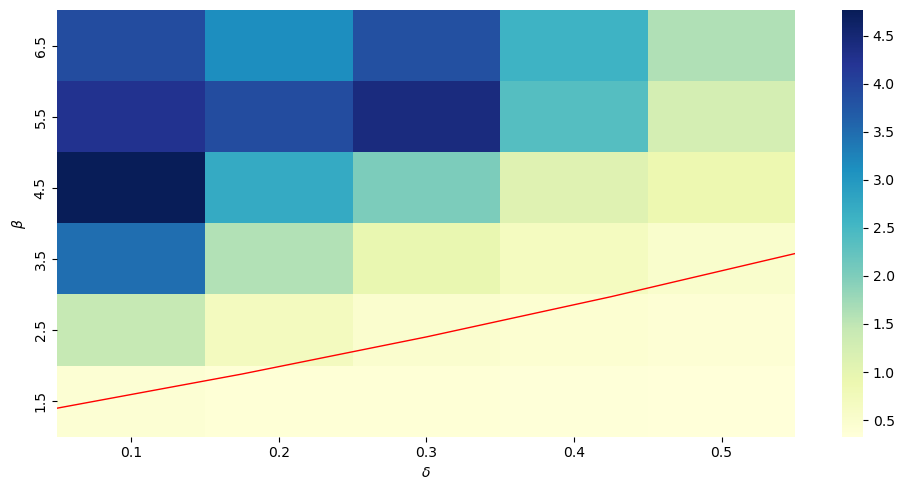

In [13]:
fig, axes = plt.subplots(1, 1, figsize=(10, 5))  # 2 rows x 4 columns
ax = axes
sns.heatmap(res_matrix_n[:, :, 0],
            xticklabels=[f"{delta:.1f}" for delta in delta_list],
            yticklabels=[f"{beta:.1f}" for beta in beta_list],
            cmap='YlGnBu',
            ax=ax)

beta_critic = beta_crit(delta_list, s0)

x_positions = np.linspace(0, len(delta_list), len(delta_list))
y_positions = np.interp(beta_critic, beta_list, np.arange(len(beta_list)))  # Map beta_critic to heatmap indices

ax.plot(x_positions, y_positions, color='red', linewidth=1, label=r'$\beta_c$')

ax.invert_yaxis()
ax.set_xlabel(r"$\delta$")
ax.set_ylabel(r"$\beta$")

plt.tight_layout()
plt.show()

In [7]:
# rew_n_list = []
rew_list = []

k = 2
env = Ants_move_special(n, Lx, Ly, delta, beta, decay_rate, eta, eta_special,
                        beta_special, delta_special, tmax, n_special, t_transient)

env.reset_objects()
env.transient()

# res = np.zeros(8)

for t in range(1000):
    
    env.update()

    env.order_parameter_s()
    env.compute_density()
    env.order_parameter_p() 
    env.avg_pher()

    mask = env.pheromones > (k*env.s0)
    G = create_graph_from_grid(mask)
    total_nodes = G.number_of_nodes()
    
    for site in env.positions[env.n:]:
        mask[site[0], site[1]] = 1

    G_hat = create_graph_from_grid(mask)
    component_map = component_map_nodes(env, G_hat)

    rews = [reward(component_map, site[0], site[1], alpha, env, total_nodes) for site in env.positions[env.n:]]
    # rews_n = [reward_n(component_map,  env, site[0], site[1], alpha)[3] for site in env.positions[env.n:]]
    #rews = [item if item is not None else [0, 0, 0] for item in rews]

    # rew_n_list.append(rews_n)
    rew_list.append(rews)

In [15]:
n = 300
Lx = 32
Ly = 32
delta = 0.3
beta = 4.5
eta = 0.01
decay_rate = 0.015
eta_special = 1
n_special = 30
t_transient = 200
tmax = 800
k = 2
beta_special = 4.5
delta_special = 0.3

env = Ants_move_special(n, Lx, Ly, delta, beta, decay_rate, eta, eta_special,
                            beta_special, delta_special, tmax, n_special, t_transient)

env.reset_objects()
env.transient()

# res = np.zeros(8)

for t in range(600):

    s0 = env.avg_pher()
    
    env.update()

    env.order_parameter_s()
    env.compute_density()
    env.order_parameter_p() 
    env.avg_pher()

    rews = [reward(env, site) for site in env.positions[env.n:]]
    # rews_n = [reward_n(component_map,  env, site[0], site[1], alpha)[3] for site in env.positions[env.n:]]
    #rews = [item if item is not None else [0, 0, 0] for item in rews]

    # rew_n_list.append(rews_n)

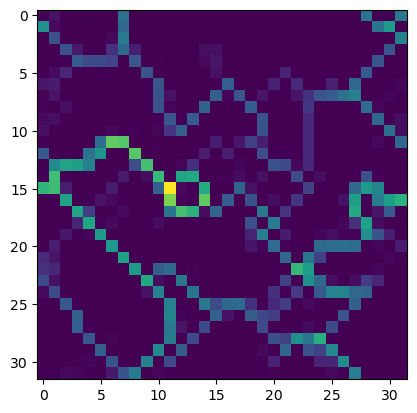

In [16]:
plt.imshow(env.pheromones)